In [ ]:
!pip install langchain==0.3.24 -q
!pip install langchain-openai -q
!pip install langchain-community -q
!pip install langgraph -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 461.3/461.3 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.0/363.0 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 29.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langgraph-prebuilt 1.1.0 requires langchain-core>=1.3.1, but you have langchain-core 0.3.86 which is incompatible.
langgraph 1.2.12 requires langchain-core<2,>=1.4.7, but you have langchain-core 0.3.86 which is incompatible.
langgraph-sdk 0.4.5 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.3.86 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━

In [ ]:
from typing import TypedDict, Annotated
from langchain_core.messages import HumanMessage
from langgraph.graph import add_messages, StateGraph, START, END
from langchain_openai import ChatOpenAI

In [ ]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

In [ ]:
import os
from google.colab import userdata

os.environ['OPENAI_API_KEY'] = userdata.get('API_KEY')

llm = ChatOpenAI(model = "gpt-4o-mini")

In [ ]:
def generate(state: State):
    return {
        "messages": [llm.invoke(state["messages"])]
    }

In [ ]:
def get_decision(state: State):
    post_content = state["messages"][-1].content

    print(post_content)

    print("\n")
    decision = input("Is it OK? (yes/no): ")

    if decision.lower() == "yes":
        print("Done\n")
        return "finalize"
    else:
        return "collect_feedback"

In [ ]:
def collect_feedback(state: State):
    feedback = input("How can I improve this post?")
    print("\n")
    return {
        "messages": [HumanMessage(content=feedback)]
    }

In [ ]:
graph = StateGraph(State)

graph.add_node("generate", generate)
graph.add_node("collect_feedback", collect_feedback)

graph.add_edge(START, "generate")

graph.add_conditional_edges(
    "generate",
    get_decision,
    {
        "finalize": END,
        "collect_feedback": "collect_feedback"
    }
)

graph.add_edge("collect_feedback", "generate")

app = graph.compile()

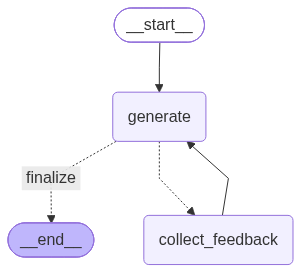

In [ ]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
response = app.invoke({
    "messages": [HumanMessage(content="what is agentic ai")]
})

print(response)

Agentic AI, often referred to as "agentive AI," refers to artificial intelligence systems that possess a certain level of autonomy and decision-making capability. This type of AI is designed to act on behalf of users, making decisions and performing tasks based on its programming, learning, or understanding of a given situation.

Key characteristics of agentic AI include:

1. **Autonomy**: Agentic AI systems can operate independently to some extent, enabling them to perform tasks or make decisions without constant human input.

2. **Goal-directed behavior**: These systems often have specific objectives or tasks they are designed to accomplish, which can involve reasoning, planning, and executing actions to achieve those goals.

3. **Learning and adaptability**: Many agentic AI systems can learn from their experiences, allowing them to adapt their behavior over time based on feedback or new information.

4. **Interaction with the environment**: Agentic AI often interacts with its surrou